# Лабораторная работа №3. Кластеризация

Системы искусственного интеллекта и машинное обучение

Ненашкин В. Д., группа АВТ-313, НГТУ

Группируем образцы вин по химическому составу и сравниваем качество и устойчивость разбиений K-means и метода Уорда. В дополнительной части проверяем глубокую кластеризацию DEC на том же наборе.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.cluster.hierarchy import dendrogram, linkage
from scipy.spatial.distance import cdist, pdist
from scipy.stats import norm, shapiro
from sklearn.cluster import AgglomerativeClustering, KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import (
    adjusted_rand_score, calinski_harabasz_score, davies_bouldin_score,
    rand_score, silhouette_samples, silhouette_score,
)
from sklearn.metrics.cluster import pair_confusion_matrix
from sklearn.preprocessing import StandardScaler

RANDOM_STATE = 42
FIGURES = Path("runtime/figures")
RESULTS = Path("runtime/results")
FIGURES.mkdir(parents=True, exist_ok=True)
RESULTS.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid", font_scale=1.0)
plt.rcParams["figure.dpi"] = 115

## 1. Данные и дескриптивный анализ

Набор Wine из UCI Machine Learning Repository содержит результаты химического анализа вин из одного региона Италии. Единицы измерения в описании набора не приведены. Признаки описывают содержание спирта, яблочной кислоты, золы, магния, фенольных соединений и пролина, щёлочность золы, интенсивность и оттенок цвета, отношение оптических плотностей OD280/OD315. Столбец `class` содержит сорт. Его исключаем из признаков и обращаемся к нему после выбора всех настроек.

In [2]:
data = pd.read_csv("wine.csv")
X_raw = data.drop(columns="class").astype(float)
overview = pd.DataFrame({
    "Тип в CSV": data.dtypes.astype(str),
    "Пропуски": data.isna().sum(),
    "Различных значений": data.nunique(),
})
print(f"Объектов: {len(X_raw)}, признаков: {X_raw.shape[1]}")
print(f"Дубли среди признаков: {X_raw.duplicated().sum()}")
display(overview)
display(X_raw.head())

Объектов: 178, признаков: 13
Дубли среди признаков: 0


,Тип в CSV,Пропуски,Различных значений
class,int64,0,3
alcohol,float64,0,126
malic_acid,float64,0,133
ash,float64,0,79
alcalinity_of_ash,float64,0,63
magnesium,int64,0,53
total_phenols,float64,0,97
flavanoids,float64,0,132
nonflavanoid_phenols,float64,0,39
proanthocyanins,float64,0,101


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280_od315,proline
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0


В таблице 178 образцов, 13 числовых признаков и столбец с сортом. Магний и пролин записаны целыми числами, остальные признаки имеют дробные значения. Пропусков и дубликатов среди строк признаков нет, поэтому заполнять или удалять строки на этапе загрузки не пришлось.

In [3]:
descriptive = X_raw.describe().T
display(descriptive.round(3))
descriptive.to_csv(RESULTS / "descriptive.csv")

,count,mean,std,min,25%,50%,75%,max
alcohol,178.0,13.001,0.812,11.03,12.362,13.050,13.678,14.83
malic_acid,178.0,2.336,1.117,0.74,1.602,1.865,3.082,5.80
ash,178.0,2.367,0.274,1.36,2.210,2.360,2.558,3.23
alcalinity_of_ash,178.0,19.495,3.340,10.60,17.200,19.500,21.500,30.00
magnesium,178.0,99.742,14.282,70.00,88.000,98.000,107.000,162.00
total_phenols,178.0,2.295,0.626,0.98,1.742,2.355,2.800,3.88
flavanoids,178.0,2.029,0.999,0.34,1.205,2.135,2.875,5.08
nonflavanoid_phenols,178.0,0.362,0.124,0.13,0.270,0.340,0.438,0.66
proanthocyanins,178.0,1.591,0.572,0.41,1.250,1.555,1.950,3.58
color_intensity,178.0,5.058,2.318,1.28,3.220,4.690,6.200,13.00


Медиана содержания спирта равна 13,05 при диапазоне 11,03–14,83. Для пролина медиана равна 673,5, а значения лежат между 278 и 1680. Признаки различаются по масштабу, поэтому расстояния будем считать после стандартизации.

In [4]:
normality = pd.DataFrame({
    "Асимметрия": X_raw.skew(),
    "p Шапиро–Уилка": [shapiro(X_raw[col]).pvalue for col in X_raw],
}, index=X_raw.columns)
display(normality.round(4))

,Асимметрия,p Шапиро–Уилка
alcohol,-0.0515,0.0200
malic_acid,1.0397,0.0000
ash,-0.1767,0.0387
alcalinity_of_ash,0.2130,0.2639
magnesium,1.0982,0.0000
total_phenols,0.0866,0.0044
flavanoids,0.0253,0.0000
nonflavanoid_phenols,0.4502,0.0001
proanthocyanins,0.5171,0.0145
color_intensity,0.8686,0.0000


При отдельной проверке каждого признака на уровне 0,05 у 12 признаков из 13 получены меньшие p-значения. Для щёлочности золы $p=0{,}264$, поэтому тест не даёт оснований отвергнуть нормальность этого признака. Нулевые значения в таблице получились из-за округления. Тест используется как описательная проверка вместе с гистограммами.

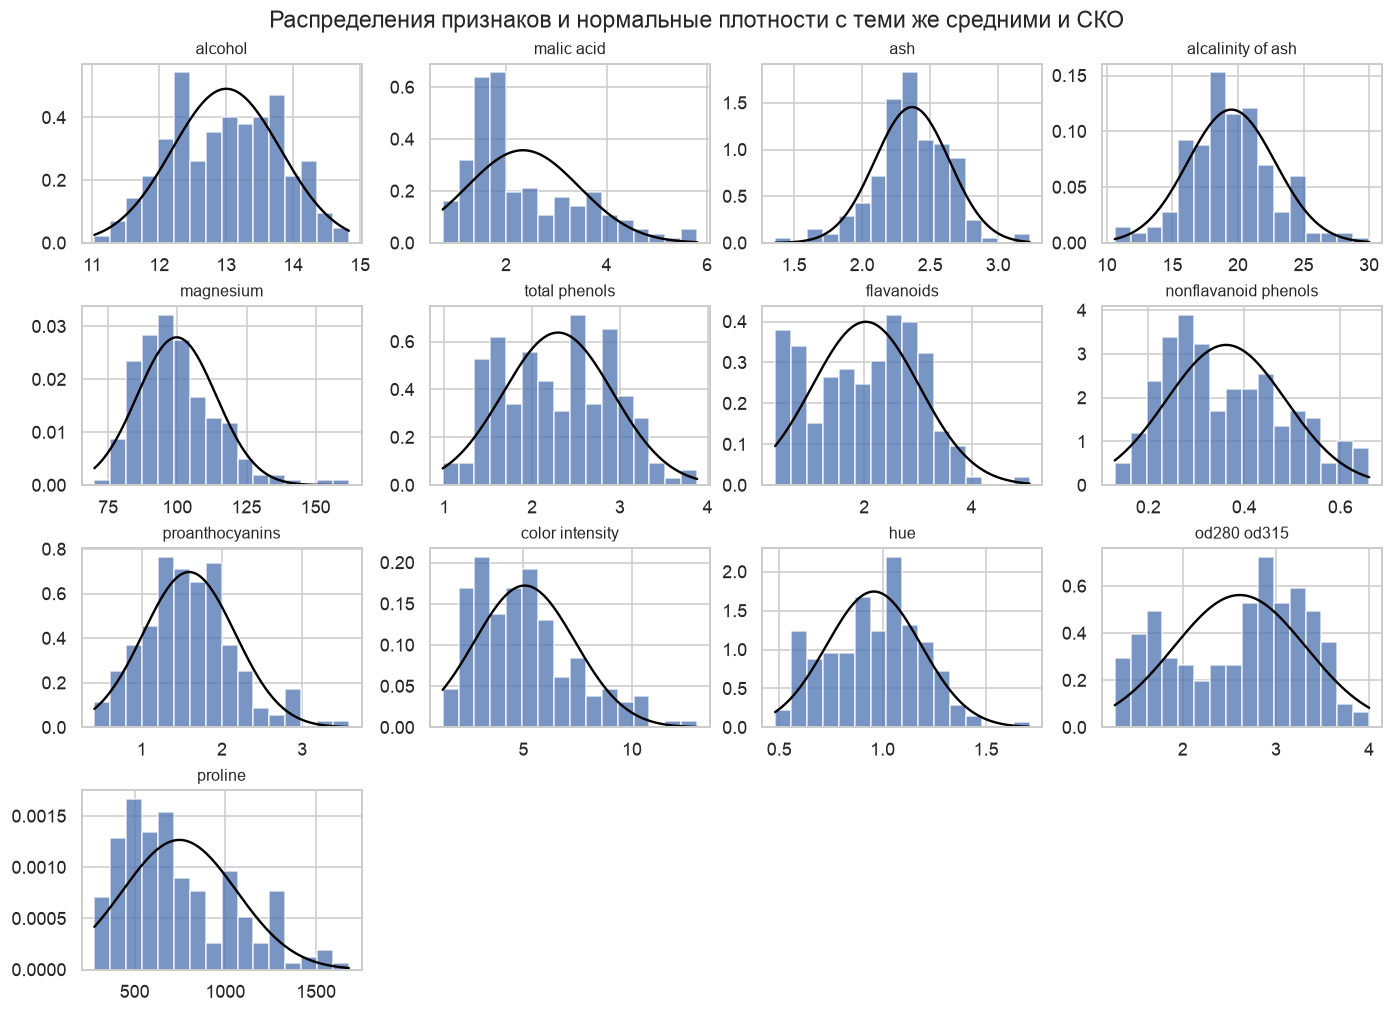

In [5]:
fig, axes = plt.subplots(4, 4, figsize=(12, 8.7), layout="constrained")
for ax, col in zip(axes.flat, X_raw):
    values = X_raw[col]
    grid = np.linspace(values.min(), values.max(), 150)
    ax.hist(values, bins=16, density=True, alpha=0.75, edgecolor="white")
    ax.plot(grid, norm.pdf(grid, values.mean(), values.std()), color="black")
    ax.set_title(col.replace("_", " "), fontsize=10)
for ax in axes.flat[X_raw.shape[1]:]:
    ax.axis("off")
fig.suptitle("Распределения признаков и нормальные плотности с теми же средними и СКО")
fig.savefig(FIGURES / "histograms.png", dpi=150)
plt.show()

У яблочной кислоты и магния заметны длинные правые хвосты. На гистограмме флавоноидов видно несколько пиков при асимметрии, близкой к нулю. K-means и метод Уорда рассчитывают расстояния и не требуют нормального распределения каждого признака.

In [6]:
q1, q3 = X_raw.quantile(0.25), X_raw.quantile(0.75)
iqr = q3 - q1
outside = X_raw.lt(q1 - 1.5 * iqr) | X_raw.gt(q3 + 1.5 * iqr)
outlier_rows = outside.any(axis=1)
display(outside.sum().rename("Значений за границами IQR").to_frame())
print(f"Образцов хотя бы с одним таким значением: {outlier_rows.sum()}")

,Значений за границами IQR
alcohol,0
malic_acid,3
ash,3
alcalinity_of_ash,4
magnesium,4
total_phenols,0
flavanoids,0
nonflavanoid_phenols,0
proanthocyanins,2
color_intensity,4


Образцов хотя бы с одним таким значением: 17


За границы $Q_1-1{,}5 IQR$ и $Q_3+1{,}5 IQR$ выходят отдельные значения у 17 образцов. Больше всего таких значений у щёлочности золы, магния и интенсивности цвета, по четыре. Основные разбиения строятся на всех образцах. В разделе 5 проверим, как изменятся группы без этих строк.

## 2. Масштабирование и структура данных

Оба классических метода используют евклидовы расстояния. После преобразования $z_j=(x_j-\mu_j)/\sigma_j$ изменение на одно стандартное отклонение даёт одинаковый вклад в расстояние для каждого признака. Для описательной кластеризации стандартизуем все 178 объектов. При проверках с подвыборками и валидации автоэнкодера оцениваем параметры масштабирования на соответствующей обучающей части.

In [7]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_raw)
scale_check = pd.DataFrame({
    "СКО до": scaler.scale_,
    "Среднее после": X_scaled.mean(axis=0),
    "СКО после": X_scaled.std(axis=0),
}, index=X_raw.columns)
display(scale_check.round(4) + 0.0)

,СКО до,Среднее после,СКО после
alcohol,0.8095,0.0,1.0
malic_acid,1.1140,0.0,1.0
ash,0.2736,0.0,1.0
alcalinity_of_ash,3.3302,0.0,1.0
magnesium,14.2423,0.0,1.0
total_phenols,0.6241,0.0,1.0
flavanoids,0.9960,0.0,1.0
nonflavanoid_phenols,0.1241,0.0,1.0
proanthocyanins,0.5707,0.0,1.0
color_intensity,2.3118,0.0,1.0


До преобразования СКО пролина равно 314,02, а у нефлавоноидных фенолов 0,124. После стандартизации среднее каждого признака близко к нулю, СКО равно единице. Так исходные единицы измерения перестают определять вклад признака в расстояние.

In [8]:
pca = PCA(n_components=2)
projection = pca.fit_transform(X_scaled)
pca_contribution = pd.Series(
    np.square(pca.components_).T @ pca.explained_variance_ratio_,
    index=X_raw.columns,
).sort_values(ascending=False)
spearman = X_raw.corr(method="spearman")
upper = np.triu_indices_from(spearman, k=1)
correlations = pd.Series(spearman.to_numpy()[upper],
    index=pd.MultiIndex.from_arrays([X_raw.columns[upper[0]], X_raw.columns[upper[1]]]))
print("Доля дисперсии по компонентам:", pca.explained_variance_ratio_.round(4))
display(pca_contribution.rename("Вклад в дисперсию двух компонент").to_frame().round(4))
display(correlations.sort_values(key=abs, ascending=False).head(5).rename("ρ Спирмена").round(3))

Доля дисперсии по компонентам: [0.362  0.1921]


,Вклад в дисперсию двух компонент
flavanoids,0.0648
total_phenols,0.0572
color_intensity,0.0568
od280_od315,0.0564
proline,0.0553
alcohol,0.0525
hue,0.0468
proanthocyanins,0.0359
nonflavanoid_phenols,0.0324
malic_acid,0.0315


total_phenols  flavanoids         0.879
flavanoids     od280_od315        0.742
               proanthocyanins    0.730
total_phenols  od280_od315        0.687
               proanthocyanins    0.667
Name: ρ Спирмена, dtype: float64

Чтобы оценить вклад признака в две главные компоненты, складываем квадраты его весов с поправкой на долю дисперсии каждой компоненты. Лидируют флавоноиды, общие фенолы, интенсивность цвета и OD280/OD315. Ранговая корреляция фенолов и флавоноидов равна 0,879. В кластеризации сохранены все 13 признаков, поскольку вклад в первые две компоненты описывает только часть общей дисперсии. Четыре признака с наибольшими вкладами показаны на матрице рассеивания.

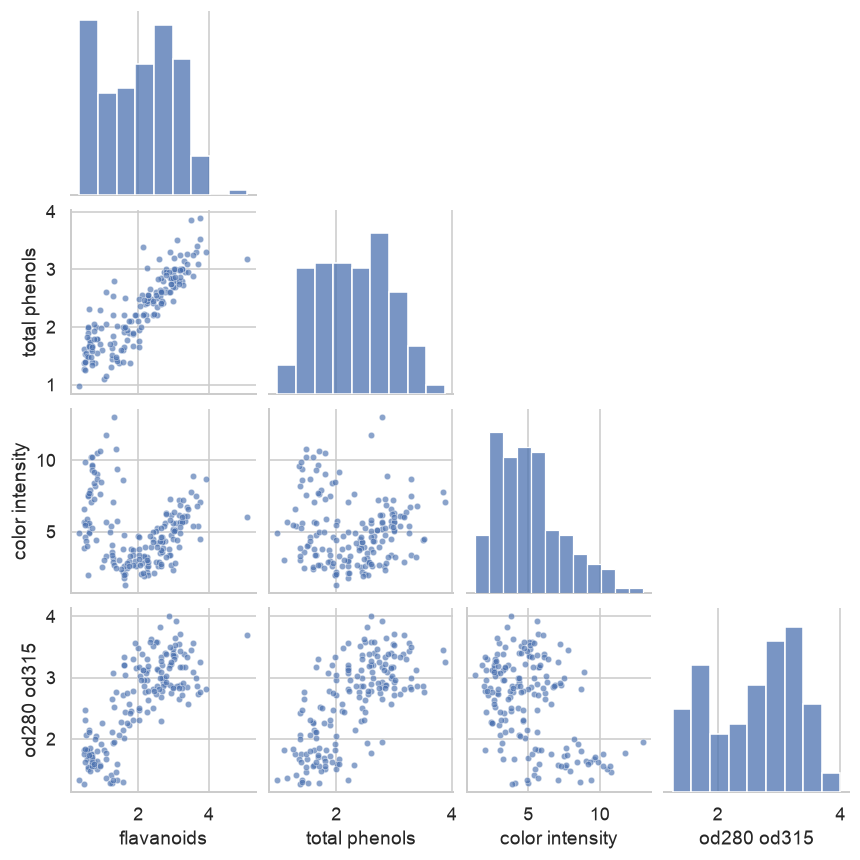

In [9]:
pair_features = pca_contribution.index[:4].tolist()
pairs = sns.pairplot(
    X_raw[pair_features].rename(columns=lambda name: name.replace("_", " ")),
    height=1.9, diag_kind="hist", corner=True,
    plot_kws={"s": 16, "alpha": 0.65},
)
pairs.figure.savefig(FIGURES / "scatter_matrix.png", dpi=150, bbox_inches="tight")
plt.show()

На паре «общие фенолы и флавоноиды» видна наклонная полоса. В парах с интенсивностью цвета видны области разной плотности и перекрытие, чётких границ между всеми группами нет. По двум координатам нельзя надёжно оценить размеры групп и выбрать их число. Сравним два метода компактных групп, K-means и Уорда, а число групп подберём по всем признакам.

## 3. K-means и агломеративная кластеризация

K-means минимизирует сумму квадратов расстояний до ближайшего центра. Метод Уорда на каждом шаге объединяет две группы с наименьшим увеличением внутригрупповой суммы квадратов. Дендрограмма показывает последовательность слияний.

In [10]:
def internal_metrics(values, labels):
    count = np.unique(labels).size
    if not 2 <= count < len(labels):
        return {"Silhouette": np.nan, "Calinski–Harabasz": np.nan, "Davies–Bouldin": np.nan}
    return {
        "Silhouette": silhouette_score(values, labels),
        "Calinski–Harabasz": calinski_harabasz_score(values, labels),
        "Davies–Bouldin": davies_bouldin_score(values, labels),
    }

k_grid = range(1, 11)
inertia = []
k_rows = []
for k in k_grid:
    model = KMeans(n_clusters=k, init="k-means++", n_init=10, random_state=RANDOM_STATE)
    labels = model.fit_predict(X_scaled)
    inertia.append(model.inertia_)
    k_rows.append({"k": k, "Инерция": model.inertia_, **internal_metrics(X_scaled, labels)})
k_search = pd.DataFrame(k_rows).set_index("k")
display(k_search.round(4))
k_search.to_csv(RESULTS / "kmeans_grid.csv")

,Инерция,Silhouette,Calinski–Harabasz,Davies–Bouldin
k,,,,
1,2314.0000,NaN,NaN,NaN
2,1658.7589,0.2593,69.5233,1.5260
3,1277.9285,0.2849,70.9400,1.3892
4,1175.4283,0.2602,56.1814,1.7969
5,1109.5127,0.2016,46.9522,1.8083
6,1046.0023,0.2372,41.7008,1.5544
7,981.5952,0.2036,38.6855,1.6606
8,935.2012,0.1570,35.8053,1.7409
9,889.8929,0.1499,33.8066,1.7083


При переходе от $k=2$ к $k=3$ инерция уменьшается с 1658,76 до 1277,93, а силуэт растёт с 0,2593 до 0,2849. При $k=4$ инерция продолжает снижаться, но силуэт уменьшается до 0,2602. Одной инерции для выбора $k$ недостаточно. При $k=1$ метрики разделения не определены.

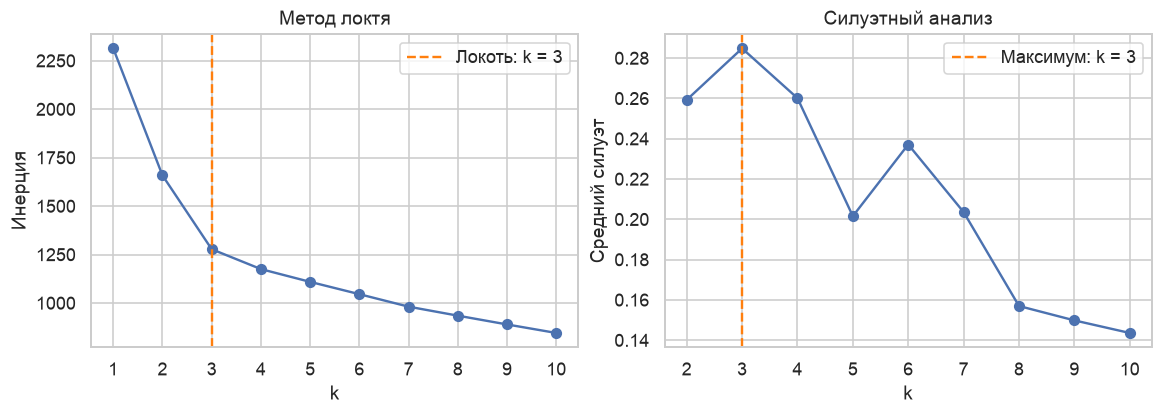

In [11]:
k_axis = (np.array(list(k_grid)) - 1) / (max(k_grid) - 1)
inertia_axis = (np.array(inertia) - inertia[-1]) / (inertia[0] - inertia[-1])
elbow_k = int(np.argmax(1 - k_axis - inertia_axis) + 1)
kmeans_k = int(k_search["Silhouette"].idxmax())

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5), layout="constrained")
axes[0].plot(k_grid, inertia, "o-")
axes[0].axvline(elbow_k, color="tab:orange", linestyle="--", label=f"Локоть: k = {elbow_k}")
axes[0].set(xlabel="k", ylabel="Инерция", title="Метод локтя", xticks=list(k_grid))
axes[0].legend()
axes[1].plot(k_search.index[1:], k_search["Silhouette"].iloc[1:], "o-")
axes[1].axvline(kmeans_k, color="tab:orange", linestyle="--", label=f"Максимум: k = {kmeans_k}")
axes[1].set(xlabel="k", ylabel="Средний силуэт", title="Силуэтный анализ", xticks=list(k_grid)[1:])
axes[1].legend()
fig.savefig(FIGURES / "elbow_silhouette.png", dpi=150)
plt.show()

После нормировки осей локоть ищется по наибольшему отступу кривой вниз от прямой между крайними точками. Локоть и максимум силуэта приходятся на $k=3$. Большие $k$ дают меньшую инерцию, но разделение по силуэту хуже.

,Silhouette,Calinski–Harabasz,Davies–Bouldin
k,,,
2,0.2670,65.3608,1.4118
3,0.2774,67.6475,1.4186
4,0.2258,51.4641,1.7887
5,0.1867,43.6793,1.9229
6,0.1797,39.1290,1.8123
7,0.1869,36.2905,1.6616
8,0.1883,34.0214,1.5514
9,0.1917,32.4603,1.5452
10,0.1986,30.5367,1.4755


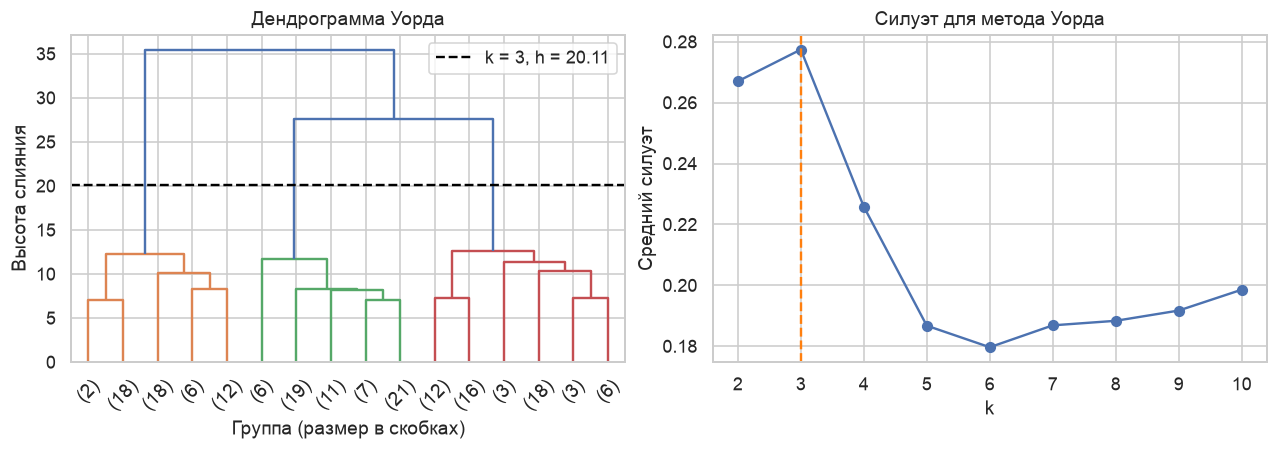

In [12]:
ward_rows = []
for k in range(2, 11):
    model = AgglomerativeClustering(n_clusters=k, linkage="ward", metric="euclidean")
    labels = model.fit_predict(X_scaled)
    ward_rows.append({"k": k, **internal_metrics(X_scaled, labels)})
ward_search = pd.DataFrame(ward_rows).set_index("k")
ward_k = int(ward_search["Silhouette"].idxmax())
display(ward_search.round(4))

tree = linkage(X_scaled, method="ward", metric="euclidean")
height = (tree[-ward_k, 2] + tree[-ward_k + 1, 2]) / 2
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), layout="constrained")
dendrogram(tree, truncate_mode="lastp", p=16, color_threshold=height, ax=axes[0])
axes[0].axhline(height, color="black", linestyle="--", label=f"k = {ward_k}, h = {height:.2f}")
axes[0].set(title="Дендрограмма Уорда", xlabel="Группа (размер в скобках)", ylabel="Высота слияния")
axes[0].tick_params(axis="x", labelrotation=45)
axes[0].legend()
axes[1].plot(ward_search.index, ward_search["Silhouette"], "o-")
axes[1].axvline(ward_k, color="tab:orange", linestyle="--")
axes[1].set(title="Силуэт для метода Уорда", xlabel="k", ylabel="Средний силуэт", xticks=ward_search.index)
fig.savefig(FIGURES / "ward_selection.png", dpi=150)
plt.show()

Для метода Уорда наибольший силуэт 0,2774 получен при $k=3$. Горизонтальный разрез дендрограммы на высоте 20,11 пересекает три ветви. По оси высоты показаны расстояния слияний по Уорду.

In [13]:
kmeans = KMeans(n_clusters=kmeans_k, init="k-means++", n_init=10, random_state=RANDOM_STATE)
ward = AgglomerativeClustering(n_clusters=ward_k, linkage="ward", metric="euclidean")
labels_kmeans = kmeans.fit_predict(X_scaled)
labels_ward = ward.fit_predict(X_scaled)
classic_labels = {"K-means": labels_kmeans, "Уорд": labels_ward}
classic_models = {
    "K-means": lambda: KMeans(n_clusters=kmeans_k, init="k-means++", n_init=10, random_state=RANDOM_STATE),
    "Уорд": lambda: AgglomerativeClustering(n_clusters=ward_k, linkage="ward", metric="euclidean"),
}
size_table = pd.DataFrame({name: pd.Series(labels).value_counts().sort_index() for name, labels in classic_labels.items()})
size_table.index.name = "Номер кластера"
display(size_table)
display(pd.DataFrame({"K-means": labels_kmeans, "Уорд": labels_ward}).head(10))
print(f"Инерция K-means: {kmeans.inertia_:.4f}")

,K-means,Уорд
Номер кластера,,
0,65,58
1,51,56
2,62,64


,K-means,Уорд
0,2,2
1,2,2
2,2,2
3,2,2
4,2,2
5,2,2
6,2,2
7,2,2
8,2,2
9,2,2


Инерция K-means: 1277.9285


K-means дал группы из 65, 51 и 62 образцов, метод Уорда из 58, 56 и 64. Номера кластеров произвольны. Первые десять строк в обеих моделях попали в кластер с номером 2.

## 4. Метрики, расстояния и центры

Силуэт сопоставляет среднее расстояние до своей группы и до ближайшей другой группы. Больший силуэт и больший индекс Калински–Харабаша соответствуют лучшему разделению по этим критериям. Для индекса Дэвиса–Болдина предпочтительны меньшие значения. Все три метрики здесь рассчитаны по одним и тем же 13 стандартизованным признакам.

In [14]:
classic_scores = pd.DataFrame({
    name: internal_metrics(X_scaled, labels) for name, labels in classic_labels.items()
}).T
display(classic_scores.round(4))
display(pd.crosstab(labels_kmeans, labels_ward, rownames=["K-means"], colnames=["Уорд"]))
print(f"ARI между двумя разбиениями: {adjusted_rand_score(labels_kmeans, labels_ward):.4f}")

,Silhouette,Calinski–Harabasz,Davies–Bouldin
K-means,0.2849,70.9400,1.3892
Уорд,0.2774,67.6475,1.4186


Уорд,0,1,2
K-means,,,
0,57,5,3
1,0,51,0
2,1,0,61


ARI между двумя разбиениями: 0.8530


У K-means выше силуэт и индекс Калински–Харабаша, а индекс Дэвиса–Болдина ниже. Разница силуэтов составляет около 0,0074. ARI 0,853 между двумя разбиениями показывает, что большинство пар сгруппировано сходно. Например, 51 образец группы 1 K-means попал в одну группу Уорда.

In [15]:
def cluster_centers(values, labels):
    return np.array([values[labels == i].mean(axis=0) for i in np.unique(labels)])

classic_centers = {
    "K-means": kmeans.cluster_centers_,
    "Уорд": cluster_centers(X_scaled, labels_ward),
}
distance_rows = []
for name, labels in classic_labels.items():
    centers = classic_centers[name]
    for i, center in enumerate(centers):
        members = X_scaled[labels == i]
        pairwise = pdist(members)
        to_center = np.linalg.norm(members - center, axis=1)
        distance_rows.append({
            "Метод": name, "Кластер": i, "Размер": len(members),
            "Среднее попарное d": pairwise.mean() if len(pairwise) else 0.0,
            "Среднее d до центра": to_center.mean(),
            "Средний квадрат d до центра": np.square(to_center).mean(),
        })
    print(name)
    display(pd.DataFrame(cdist(centers, centers)).round(3))
distance_table = pd.DataFrame(distance_rows).set_index(["Метод", "Кластер"])
display(distance_table.round(3))
distance_table.to_csv(RESULTS / "cluster_distances.csv")

K-means


,0,1,2
0,0.000,3.973,3.596
1,3.973,0.000,5.029
2,3.596,5.029,0.000


Уорд


,0,1,2
0,0.000,3.867,3.545
1,3.867,0.000,4.852
2,3.545,4.852,0.000


Размер  Среднее попарное d  Среднее d до центра  \
Метод   Кластер                                                    
K-means 0            65               4.010                2.789   
        1            51               3.493                2.445   
        2            62               3.364                2.337   
Уорд    0            58               3.955                2.745   
        1            56               3.698                2.587   
        2            64               3.386                2.354   

                 Средний квадрат d до центра  
Метод   Кластер                               
K-means 0                              8.644  
        1                              6.435  
        2                              6.256  
Уорд    0                              8.531  
        1                              7.287  
        2                              6.284

Берём разные пары объектов внутри группы и усредняем расстояния между ними. Для оценки компактности усредняем квадраты расстояний до центра. Чем меньше это значение, тем компактнее группа. У обоих методов группа 0 в среднем дальше всего от своего центра. Наиболее удалены центры 1 и 2, расстояния равны 5,029 у K-means и 4,852 у Уорда.

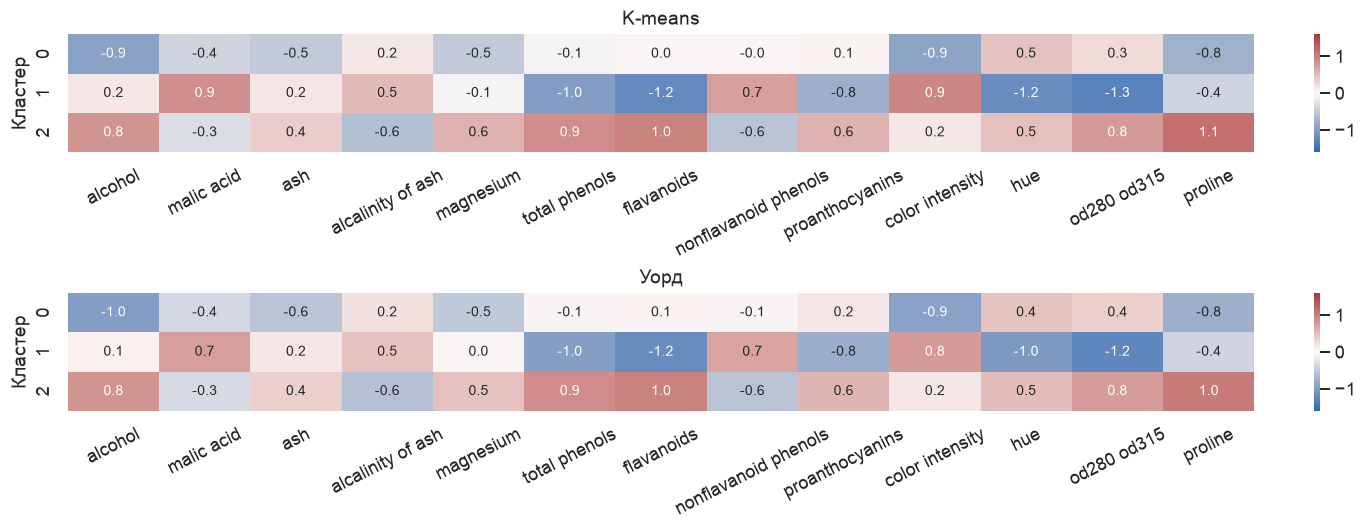

K-means: центры в исходном масштабе


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280_od315,proline
0,12.251,1.897,2.231,20.063,92.738,2.248,2.050,0.358,1.624,2.973,1.063,2.803,510.169
1,13.134,3.307,2.418,21.241,98.667,1.684,0.819,0.452,1.146,7.235,0.692,1.697,619.059
2,13.677,1.998,2.466,17.463,107.968,2.848,3.003,0.292,1.922,5.454,1.065,3.163,1100.226


Уорд: центры в исходном масштабе


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280_od315,proline
0,12.204,1.939,2.215,20.209,92.552,2.263,2.088,0.355,1.687,2.895,1.060,2.862,501.431
1,13.062,3.167,2.413,21.004,99.857,1.694,0.848,0.449,1.129,6.850,0.721,1.727,624.946
2,13.669,1.970,2.463,17.528,106.156,2.850,3.010,0.291,1.908,5.450,1.071,3.158,1076.047


In [16]:
fig, axes = plt.subplots(2, 1, figsize=(11.8, 4.5), layout="constrained")
for ax, (name, centers) in zip(axes, classic_centers.items()):
    heat = pd.DataFrame(centers, columns=X_raw.columns.str.replace("_", " "))
    sns.heatmap(heat, annot=True, fmt=".1f", cmap="vlag", center=0,
                vmin=-1.6, vmax=1.6, ax=ax, annot_kws={"fontsize": 9})
    ax.set(title=name, ylabel="Кластер")
    ax.tick_params(axis="x", labelrotation=27)
fig.savefig(FIGURES / "cluster_centers.png", dpi=150)
plt.show()

profiles = {}
for name, centers in classic_centers.items():
    profiles[name] = pd.DataFrame(scaler.inverse_transform(centers), columns=X_raw.columns)
    print(f"{name}: центры в исходном масштабе")
    display(profiles[name].round(3))

У K-means центр группы 0 имеет наименьшую интенсивность цвета 2,973 и пролин 510,169. Для группы 1 характерна наибольшая интенсивность цвета 7,235 и наименьшее содержание флавоноидов 0,819. Группа 2 выделяется пролином 1100,226 и флавоноидами 3,003. Метод Уорда даёт группы с тем же порядком средних по этим признакам.

## 5. Визуализация и устойчивость

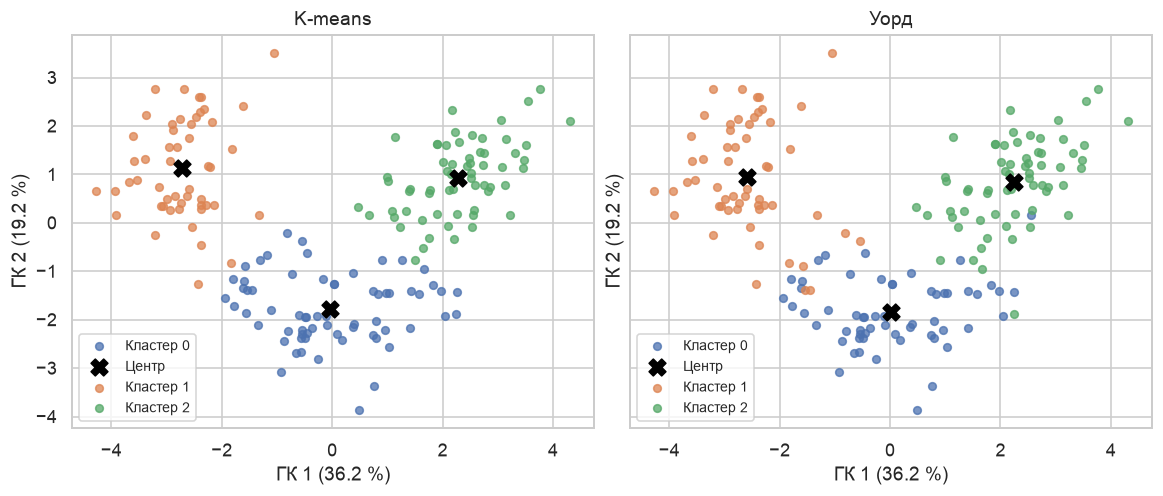

In [17]:
explained = pca.explained_variance_ratio_ * 100
fig, axes = plt.subplots(1, 2, figsize=(10, 4.2), sharex=True, sharey=True, layout="constrained")
for ax, (name, labels) in zip(axes, classic_labels.items()):
    centers_2d = pca.transform(classic_centers[name])
    for i in np.unique(labels):
        points = projection[labels == i]
        ax.scatter(points[:, 0], points[:, 1], s=23, alpha=0.75, label=f"Кластер {i}")
        ax.scatter(*centers_2d[i], s=110, color="black", marker="X",
                   label="Центр" if i == 0 else None)
    ax.set(title=name, xlabel=f"ГК 1 ({explained[0]:.1f} %)", ylabel=f"ГК 2 ({explained[1]:.1f} %)")
    ax.legend(fontsize=9)
fig.savefig(FIGURES / "clusters_pca.png", dpi=150)
plt.show()

Две компоненты вместе объясняют 55,4 % общей дисперсии. Первая компонента объясняет 36,2 % общей дисперсии. На плоскости видны три области с переходами между группами 0 и 1. Оба метода строили разбиения по 13 признакам. PCA используется для изображения меток и центров.

,Метод,Кластер,Средний силуэт,Отрицательных значений
0,K-means,0,0.177,7
1,K-means,1,0.351,0
2,K-means,2,0.343,0
3,Уорд,0,0.190,3
4,Уорд,1,0.307,3
5,Уорд,2,0.330,2


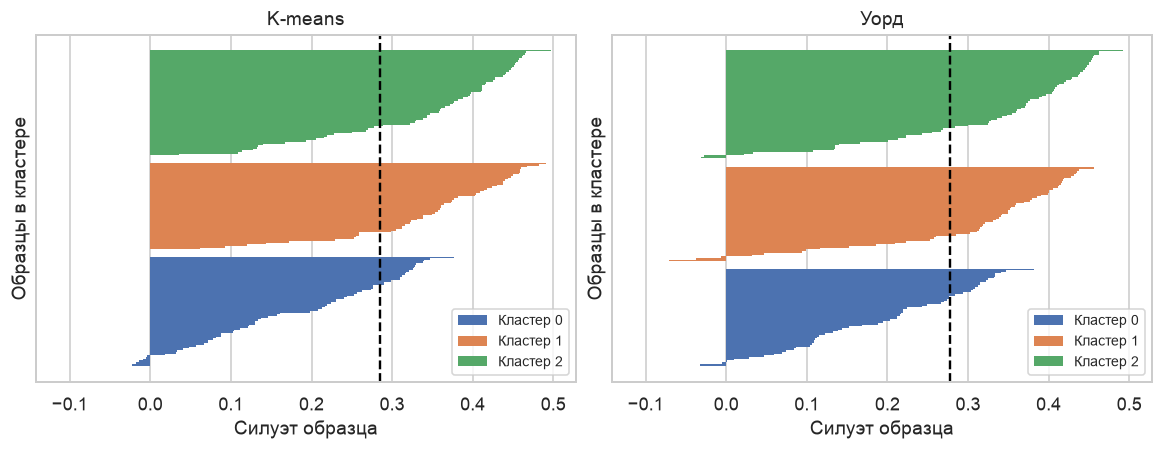

In [18]:
silhouettes = []
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), sharex=True, layout="constrained")
for ax, (name, labels) in zip(axes, classic_labels.items()):
    values = silhouette_samples(X_scaled, labels)
    start = 0
    for i in np.unique(labels):
        group = np.sort(values[labels == i])
        steps = np.arange(start, start + len(group))
        ax.fill_betweenx(steps, 0, group, step="mid", linewidth=0, label=f"Кластер {i}")
        silhouettes.append({"Метод": name, "Кластер": i, "Средний силуэт": group.mean(),
                            "Отрицательных значений": int((group < 0).sum())})
        start += len(group) + 4
    ax.axvline(values.mean(), color="black", linestyle="--")
    ax.set(title=name, xlabel="Силуэт образца", ylabel="Образцы в кластере", yticks=[])
    ax.legend(fontsize=9)
display(pd.DataFrame(silhouettes).round(3))
fig.savefig(FIGURES / "silhouette_samples.png", dpi=150)
plt.show()

Пунктир отмечает средний силуэт по всем объектам. У K-means семь отрицательных силуэтов, все в группе 0. У метода Уорда их восемь, они есть во всех трёх группах. Для таких точек среднее расстояние до соседней группы меньше, чем до своей.

In [19]:
rng = np.random.default_rng(RANDOM_STATE)
kept = np.flatnonzero(~outlier_rows.to_numpy())
sample_sets = [("Без IQR-выбросов", kept)]
for run in range(1, 11):
    subset = np.sort(rng.choice(len(X_raw), size=int(0.8 * len(X_raw)), replace=False))
    sample_sets.append((f"Подвыборка {run}", subset))
robustness_rows = []
for sample_name, subset in sample_sets:
    subset_scaled = StandardScaler().fit_transform(X_raw.iloc[subset])
    for name, factory in classic_models.items():
        labels = factory().fit_predict(subset_scaled)
        robustness_rows.append({
            "Выборка": sample_name, "Метод": name, "Размер": len(subset),
            "ARI к полному разбиению": adjusted_rand_score(classic_labels[name][subset], labels),
        })
robustness = pd.DataFrame(robustness_rows)
robustness_summary = robustness[robustness["Выборка"].str.startswith("Подвыборка")].groupby(
    "Метод")["ARI к полному разбиению"].agg(["mean", "std", "min", "max"])
display(robustness[robustness["Выборка"] == "Без IQR-выбросов"].round(3))
display(robustness_summary.round(3))
robustness.to_csv(RESULTS / "classical_stability.csv", index=False)

,Выборка,Метод,Размер,ARI к полному разбиению
0,Без IQR-выбросов,K-means,161,1.000
1,Без IQR-выбросов,Уорд,161,0.964


,mean,std,min,max
Метод,,,,
K-means,0.974,0.026,0.916,1.000
Уорд,0.894,0.053,0.807,0.959


После исключения 17 отмеченных строк ARI к полному разбиению по оставшимся 161 объектам равен 1,000 у K-means и 0,964 у Уорда. Поэтому в основных разбиениях сохранены все строки. На десяти случайных подвыборках по 142 объекта средний ARI равен 0,974 и 0,894 соответственно. В этом опыте K-means устойчивее к изменению состава выборки.

## 6. Глубокая кластеризация

Сначала автокодировщик учится восстанавливать 13 признаков вина. Затем K-means на выходе энкодера задаёт начальные центры для DEC. В DEC энкодер и центры обучаются вместе.

Размеры слоёв автоэнкодера $13 \to 8 \to d \to 8 \to 13$, где $d$ обозначает размерность скрытого представления. Два слоя по 8 нейронов с ReLU позволяют получить нелинейное преобразование при небольшом числе весов. Слой размерности $d$ и выходной слой линейные, чтобы сохранять отрицательные значения. При обучении минимизируется средняя квадратичная ошибка восстановления плюс штраф $\lambda\sum w^2$ за веса полносвязных слоёв.

In [20]:
import os
from itertools import product

os.environ.setdefault('TF_CPP_MIN_LOG_LEVEL', '2')
import tensorflow as tf
from sklearn.cluster import KMeans
from sklearn.manifold import TSNE
from sklearn.metrics import adjusted_rand_score, silhouette_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

tf.config.experimental.enable_op_determinism()
X_ae_train_raw, X_ae_val_raw = train_test_split(X_raw, test_size=0.2, random_state=RANDOM_STATE)
ae_scaler = StandardScaler().fit(X_ae_train_raw)
X_ae_train = ae_scaler.transform(X_ae_train_raw).astype('float32')
X_ae_val = ae_scaler.transform(X_ae_val_raw).astype('float32')
X_ae_screen = ae_scaler.transform(X_raw).astype('float32')
X_ae_full = X_scaled.astype('float32')

print('Обучающая часть:', X_ae_train.shape)
print('Проверочная часть:', X_ae_val.shape)

Обучающая часть: (142, 13)
Проверочная часть: (36, 13)


Для подбора параметров автоэнкодера выделены 142 обучающих и 36 проверочных образцов. Среднее и масштаб признаков для этого этапа рассчитаны на 142 образцах и применены к обеим частям. Для финального обучения используется общая стандартизация по всем 178 объектам, поскольку цель работы состоит в разбиении имеющегося набора.

In [21]:
def build_autoencoder(latent_dim, learning_rate, l2, seed):
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(seed)
    regularizer = tf.keras.regularizers.L2(l2)
    inputs = tf.keras.Input(shape=(X_ae_train.shape[1],))
    hidden = tf.keras.layers.Dense(8, activation='relu', kernel_regularizer=regularizer)(inputs)
    latent = tf.keras.layers.Dense(latent_dim, kernel_regularizer=regularizer, name='latent')(hidden)
    hidden = tf.keras.layers.Dense(8, activation='relu', kernel_regularizer=regularizer)(latent)
    outputs = tf.keras.layers.Dense(X_ae_train.shape[1], kernel_regularizer=regularizer)(hidden)
    autoencoder = tf.keras.Model(inputs, outputs)
    encoder = tf.keras.Model(inputs, latent)
    autoencoder.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=learning_rate), loss='mse')
    return autoencoder, encoder

### 6.1. Подбор параметров

Проверяются размерности $d \in \{2,3,5\}$, скорости обучения 0,001 и 0,01 и коэффициенты L2 0, 0,001 и 0,01. Для каждой размерности скорость обучения и L2 выбираются по чистой MSE на проверочной части. Среди оставшихся автоэнкодеров размерность и число кластеров определяются по максимуму силуэта в общем пространстве исходных стандартизованных признаков. Проверяем число кластеров от 2 до 6. Этот силуэт используется для выбора разбиения всего набора. Проверочная MSE оценивает только восстановление отложенных образцов.

In [22]:
AE_EPOCHS = 180
AE_BATCH_SIZE = 16
ae_grid_rows = []
ae_embeddings = {}

for dim, lr, l2 in product([2, 3, 5], [0.001, 0.01], [0.0, 0.001, 0.01]):
    ae, encoder = build_autoencoder(dim, lr, l2, RANDOM_STATE)
    ae.fit(X_ae_train, X_ae_train, epochs=AE_EPOCHS, batch_size=AE_BATCH_SIZE, verbose=0)
    ae_grid_rows.append({
        'd': dim, 'lr': lr, 'L2': l2,
        'MSE обучение': float(np.mean((X_ae_train - ae(X_ae_train).numpy()) ** 2)),
        'MSE проверка': float(np.mean((X_ae_val - ae(X_ae_val).numpy()) ** 2)),
    })
    ae_embeddings[dim, lr, l2] = encoder(X_ae_screen).numpy()

ae_grid = pd.DataFrame(ae_grid_rows)
ae_grid.to_csv(RESULTS / 'ae_grid.csv', index=False)
display(ae_grid.round(5))

,d,lr,L2,MSE обучение,MSE проверка
0,2,0.001,0.000,0.38696,0.32686
1,2,0.001,0.001,0.38641,0.32392
2,2,0.001,0.010,0.43603,0.35353
3,2,0.010,0.000,0.31687,0.32444
4,2,0.010,0.001,0.31774,0.30588
5,2,0.010,0.010,0.43161,0.33546
6,3,0.001,0.000,0.36172,0.31562
7,3,0.001,0.001,0.35980,0.30947
8,3,0.001,0.010,0.38241,0.32041
9,3,0.010,0.000,0.23165,0.24848


В сетке 18 автоэнкодировщиков, по 6 на каждую размерность. У каждого 180 эпох с пакетами по 16 объектов. По строкам с одинаковым $d$ видно, как скорость обучения и L2 меняют ошибку восстановления. Наименьшая проверочная MSE 0,16411 получена при $d=5$, скорости 0,01 и L2, равном нулю. С этой настройкой сеть точнее всего восстановила признаки отложенных образцов.

In [23]:
def cluster_silhouette(data, labels):
    if 1 < np.unique(labels).size < len(labels):
        return float(silhouette_score(data, labels))
    return np.nan

ae_best_by_dim = ae_grid.loc[ae_grid.groupby('d')['MSE проверка'].idxmin()]
ae_k_rows = []
for dim, lr, l2, _, val_mse in ae_best_by_dim.itertuples(index=False, name=None):
    z = ae_embeddings[dim, lr, l2]
    for k in range(2, 7):
        labels = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit_predict(z)
        ae_k_rows.append({'d': dim, 'lr': lr, 'L2': l2, 'k': k, 'MSE проверка': val_mse,
                          'силуэт в исходном пространстве': cluster_silhouette(X_scaled, labels)})

ae_k_grid = pd.DataFrame(ae_k_rows)
ae_choice = ae_k_grid.loc[ae_k_grid['силуэт в исходном пространстве'].idxmax()]
best_dim, k_dec = int(ae_choice['d']), int(ae_choice['k'])
best_lr, best_l2 = float(ae_choice['lr']), float(ae_choice['L2'])
ae_k_grid.to_csv(RESULTS / 'ae_k_grid.csv', index=False)
display(ae_best_by_dim.round(5))
display(ae_k_grid.pivot(index='k', columns='d', values='силуэт в исходном пространстве').round(4))
display(ae_choice.to_frame('Выбранная настройка').round(5))

,d,lr,L2,MSE обучение,MSE проверка
4,2,0.01,0.001,0.31774,0.30588
9,3,0.01,0.000,0.23165,0.24848
15,5,0.01,0.000,0.15886,0.16411


d,2,3,5
k,,,
2,0.2561,0.2452,0.2572
3,0.2752,0.2781,0.2648
4,0.2331,0.1770,0.2159
5,0.1644,0.1409,0.2342
6,0.1475,0.1084,0.2137


,Выбранная настройка
d,3.00000
lr,0.01000
L2,0.00000
k,3.00000
MSE проверка,0.24848
силуэт в исходном пространстве,0.27807


Максимальный силуэт 0,2781 получен при $d=3$, $k=3$, скорости 0,01 и L2, равном нулю. У выбранной сети проверочная MSE 0,24848. Сеть с лучшей MSE получила при $k=3$ силуэт 0,2648, поэтому для группировки выбрана размерность 3. С выбранными настройками обучаем сеть заново на всех образцах. Итоговые метки могут отличаться от найденных при подборе.

### 6.2. Уточнение кластеров DEC

Сначала расстояния от латентной координаты $z_i$ до центров $\mu_j$ переводятся в мягкие назначения по ядру Стьюдента. В числителе $q_{ij}$ стоит $(1 + \lVert z_i-\mu_j\rVert^2)^{-1}$, а знаменатель нормирует сумму по всем кластерам до единицы. Для целевого распределения $p_{ij}$ нормируются величины $q_{ij}^2 / \sum_i q_{ij}$, поэтому уверенные назначения получают больший вес.

Декодировщик используется только при восстановлении входа. Во время DEC оптимизатор Adam изменяет веса энкодера и центры, минимизируя среднее $KL(P\|Q)$ по объектам и L2-штраф энкодера. Для начальных центров берём результат K-means. На каждом шаге учитываем все объекты, а $P$ пересчитываем каждые 10 шагов.

In [24]:
class ClusteringLayer(tf.keras.layers.Layer):
    def __init__(self, n_clusters, **kwargs):
        super().__init__(**kwargs)
        self.n_clusters = n_clusters

    def build(self, input_shape):
        self.centers = self.add_weight(
            name='centers', shape=(self.n_clusters, input_shape[-1]), initializer='zeros'
        )
        super().build(input_shape)

    def call(self, z):
        distances_sq = tf.reduce_sum(tf.square(z[:, None, :] - self.centers), axis=2)
        q = 1.0 / (1.0 + distances_sq)
        return q / tf.reduce_sum(q, axis=1, keepdims=True)


def target_distribution(q):
    weights = q ** 2 / q.sum(axis=0)
    return weights / weights.sum(axis=1, keepdims=True)

In [25]:
DEC_STEPS = 400
DEC_UPDATE_INTERVAL = 10

def refine_dec(encoder, initial_centers, x):
    clustering = ClusteringLayer(len(initial_centers), name='clustering')
    model = tf.keras.Model(encoder.input, clustering(encoder.output))
    clustering.set_weights([initial_centers])
    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=best_lr),
                  loss=tf.keras.losses.KLDivergence())
    previous_labels = model(x).numpy().argmax(axis=1)
    rows = []

    for step in range(DEC_STEPS + 1):
        if step % DEC_UPDATE_INTERVAL == 0:
            q = model(x).numpy()
            p = target_distribution(q)
            labels = q.argmax(axis=1)
            kl = float(np.mean(np.sum(p * np.log(p / q), axis=1)))
            l2_penalty = float(tf.add_n(encoder.losses).numpy())
            rows.append({'шаг': step, 'KL': kl, 'L2-штраф': l2_penalty,
                         'KL + L2': kl + l2_penalty, 'среднее max q': float(q.max(axis=1).mean()),
                         'сменили кластер': int(np.count_nonzero(labels != previous_labels))})
            previous_labels = labels
        if step < DEC_STEPS:
            model.train_on_batch(x, p)

    return labels, encoder(x).numpy(), pd.DataFrame(rows)


def fit_deep_partition(seed):
    ae, encoder = build_autoencoder(best_dim, best_lr, best_l2, seed)
    ae.fit(X_ae_full, X_ae_full, epochs=AE_EPOCHS, batch_size=AE_BATCH_SIZE, verbose=0)
    z_before = encoder(X_ae_full).numpy()
    initial = KMeans(n_clusters=k_dec, n_init=10, random_state=seed).fit(z_before)
    dec_labels, z_after, history = refine_dec(encoder, initial.cluster_centers_, X_ae_full)
    return initial.labels_, z_before, dec_labels, z_after, history

Функция `fit_deep_partition` начинает каждый запуск с нового автоэнкодера и новых центров K-means. Она сохраняет метки и скрытые координаты до уточнения, после чего возвращает результат и историю DEC.

In [26]:
labels_ae, z_ae, labels_dec, z_dec, dec_log = fit_deep_partition(RANDOM_STATE)
dec_log.to_csv(RESULTS / 'dec_history.csv', index=False)
display(dec_log.iloc[::10].round(4))
print('Размеры групп до DEC:', np.bincount(labels_ae, minlength=k_dec))
print('Размеры групп после DEC:', np.bincount(labels_dec, minlength=k_dec))
ae_dec_ari = float(adjusted_rand_score(labels_ae, labels_dec))
print('ARI между разбиениями до и после DEC:', round(ae_dec_ari, 4))

,шаг,KL,L2-штраф,KL + L2,среднее max q,сменили кластер
0,0,0.0929,0.0,0.0929,0.7301,0
10,100,0.0576,0.0,0.0576,0.9089,1
20,200,0.0468,0.0,0.0468,0.9306,0
30,300,0.0416,0.0,0.0416,0.9388,0
40,400,0.0384,0.0,0.0384,0.9438,0


Размеры групп до DEC: [75 49 54]
Размеры групп после DEC: [65 56 57]
ARI между разбиениями до и после DEC: 0.7742


Энкодер и центры уточнялись 400 шагов. Мягкие назначения стали увереннее: среднее максимальное $q$ выросло с 0,7301 до 0,9438. Размеры групп изменились с 75, 49 и 54 до 65, 56 и 57. ARI между этими разбиениями равен 0,7742. KL в таблице рассчитан при пересчёте $P$, поэтому значения в соседних строках относятся к обновлённым целевым распределениям. ARI сравнивает сами разбиения и не зависит от номеров кластеров.

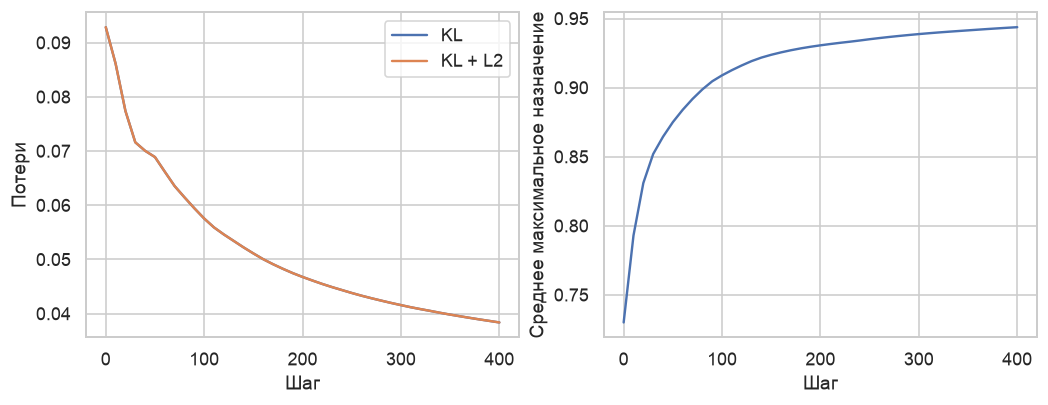

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(9.0, 3.4), layout='constrained')
axes[0].plot(dec_log['шаг'], dec_log['KL'], label='KL')
axes[0].plot(dec_log['шаг'], dec_log['KL + L2'], label='KL + L2')
axes[0].set(ylabel='Потери', xlabel='Шаг')
axes[0].legend()
axes[1].plot(dec_log['шаг'], dec_log['среднее max q'])
axes[1].set(ylabel='Среднее максимальное назначение', xlabel='Шаг')
fig.savefig(FIGURES / 'dec_history.png', dpi=170, bbox_inches='tight')
plt.show()

Слева показаны KL и сумма KL со штрафом. При выбранном L2, равном нулю, эти кривые совпадают. Справа показано среднее максимальное мягкое назначение: рост этой величины отражает уверенность модели.

### 6.3. Латентное пространство и устойчивость

Скрытые координаты до и после DEC отдельно проецируются на плоскость методом t-SNE. На каждом рисунке цвет соответствует метке своего разбиения. Силуэт в скрытом пространстве рассчитан по полным координатам, из которых построена проекция.

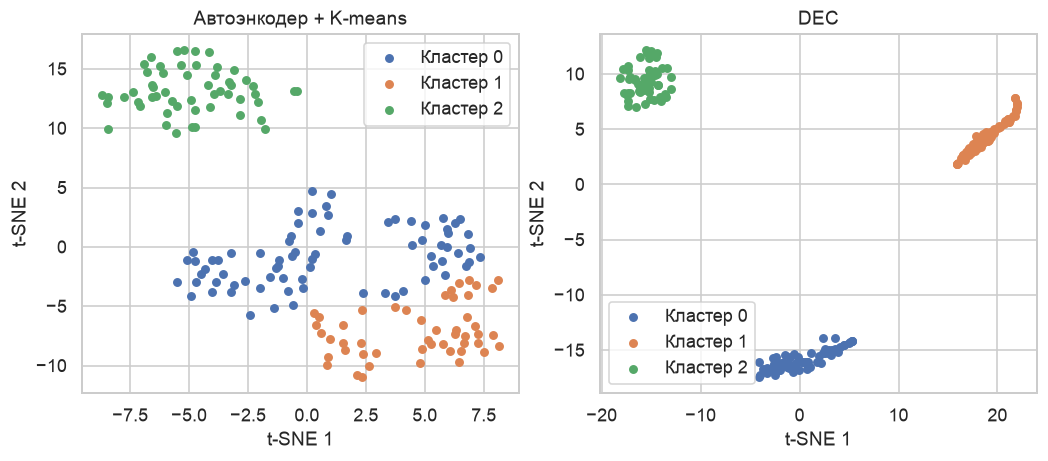

,силуэт в латентном,силуэт в исходном
метод,,
AE + K-means,0.3857,0.1636
DEC,0.8030,0.1792


In [28]:
fig, axes = plt.subplots(1, 2, figsize=(9.0, 3.9), layout='constrained')
for ax, z, labels, title in [(axes[0], z_ae, labels_ae, 'Автоэнкодер + K-means'),
                             (axes[1], z_dec, labels_dec, 'DEC')]:
    embedding = TSNE(n_components=2, perplexity=30, init='pca',
                     random_state=RANDOM_STATE).fit_transform(z)
    for group in np.unique(labels):
        points = embedding[labels == group]
        ax.scatter(points[:, 0], points[:, 1], s=21, label=f'Кластер {group}')
    ax.set(title=title, xlabel='t-SNE 1', ylabel='t-SNE 2')
    ax.legend()
fig.savefig(FIGURES / 'dec_latent_tsne.png', dpi=170, bbox_inches='tight')
plt.show()

deep_spaces = pd.DataFrame([
    {'метод': 'AE + K-means', 'силуэт в латентном': cluster_silhouette(z_ae, labels_ae),
     'силуэт в исходном': cluster_silhouette(X_scaled, labels_ae)},
    {'метод': 'DEC', 'силуэт в латентном': cluster_silhouette(z_dec, labels_dec),
     'силуэт в исходном': cluster_silhouette(X_scaled, labels_dec)},
]).set_index('метод')
display(deep_spaces.round(4))

Силуэт в скрытых координатах вырос с 0,3857 до 0,8030. В общих стандартизованных признаках рост меньше, с 0,1636 до 0,1792. Проекция t-SNE помогает увидеть соседства и возможное перекрытие, но расстояния между группами на ней зависят от проекции. Качество методов сравнивается по последнему столбцу, где все расстояния рассчитаны по одним и тем же 13 признакам.

In [29]:
deep_stability_rows = []
for seed in [7, 17, 27, 37]:
    other_ae, _, other_dec, _, _ = fit_deep_partition(seed)
    deep_stability_rows.append({
        'seed': seed,
        'ARI AE к запуску 42': float(adjusted_rand_score(labels_ae, other_ae)),
        'ARI DEC к запуску 42': float(adjusted_rand_score(labels_dec, other_dec)),
        'силуэт DEC в исходном': cluster_silhouette(X_scaled, other_dec),
        'кластеров DEC': int(np.unique(other_dec).size),
    })
deep_stability = pd.DataFrame(deep_stability_rows).set_index('seed')
deep_stability.to_csv(RESULTS / 'dec_stability.csv')
display(deep_stability.round(4))
display(deep_stability.iloc[:, :3].agg(['mean', 'min', 'max']).round(4))

deep_summary = {
    'latent_dim': best_dim, 'k': k_dec, 'lr': best_lr, 'l2': best_l2,
    'validation_mse': float(ae_choice['MSE проверка']),
    'selection_silhouette': float(ae_choice['силуэт в исходном пространстве']),
    'sizes_ae': np.bincount(labels_ae, minlength=k_dec).tolist(),
    'sizes_dec': np.bincount(labels_dec, minlength=k_dec).tolist(),
    'ari_ae_dec': ae_dec_ari,
    'kl_first': float(dec_log['KL'].iloc[0]), 'kl_last': float(dec_log['KL'].iloc[-1]),
    'confidence_first': float(dec_log['среднее max q'].iloc[0]),
    'confidence_last': float(dec_log['среднее max q'].iloc[-1]),
    'ari_ae_seed_min': float(deep_stability['ARI AE к запуску 42'].min()),
    'ari_ae_seed_max': float(deep_stability['ARI AE к запуску 42'].max()),
    'ari_dec_seed_min': float(deep_stability['ARI DEC к запуску 42'].min()),
    'ari_dec_seed_max': float(deep_stability['ARI DEC к запуску 42'].max()),
}

,ARI AE к запуску 42,ARI DEC к запуску 42,силуэт DEC в исходном,кластеров DEC
seed,,,,
7,0.4140,0.5386,0.2663,3
17,0.3556,0.5057,0.2652,3
27,0.2984,0.4030,0.2543,3
37,0.4185,0.5127,0.2828,3


,ARI AE к запуску 42,ARI DEC к запуску 42,силуэт DEC в исходном
mean,0.3716,0.4900,0.2671
min,0.2984,0.4030,0.2543
max,0.4185,0.5386,0.2828


В каждом повторе заново обучены автоэнкодер и DEC, а центры заново найдены методом K-means. Состав данных и выбранные параметры одинаковы. У DEC получено три группы во всех повторах. ARI относительно запуска с seed 42 лежит между 0,403 и 0,539, а силуэт в исходных признаках между 0,254 и 0,283. Инициализация заметно влияет на состав групп. Выборка во всех запусках одна и та же.

## 7. Сравнение разбиений с метками сортов

Сопоставляем разбиения с сортами после завершения подбора. Индекс Rand учитывает согласие и по общим, и по раздельным парам. ARI корректирует Rand на случайное согласие. Для индекса Жаккара берём пары, объединённые хотя бы в одном разбиении. Прямое сравнение номеров кластеров с номерами сортов здесь не подходит: номера кластеров произвольны.

In [30]:
y = data["class"]
all_labels = {**classic_labels, "AE + K-means": labels_ae, "DEC": labels_dec}
comparison_rows = []
for name, labels in all_labels.items():
    _, fp, fn, tp = pair_confusion_matrix(y, labels).ravel()
    union = tp + fp + fn
    comparison_rows.append({
        "Метод": name,
        "Размеры кластеров": ", ".join(str(n) for n in np.unique(labels, return_counts=True)[1]),
        **internal_metrics(X_scaled, labels),
        "Rand": rand_score(y, labels),
        "ARI": adjusted_rand_score(y, labels),
        "Жаккар (пары)": tp / union if union else 0.0,
    })
comparison = pd.DataFrame(comparison_rows).set_index("Метод")
display(comparison.round(4))
comparison.to_csv(RESULTS / "comparison.csv")

,Размеры кластеров,Silhouette,Calinski–Harabasz,Davies–Bouldin,Rand,ARI,Жаккар (пары)
Метод,,,,,,,
K-means,"65, 51, 62",0.2849,70.9400,1.3892,0.9543,0.8975,0.8725
Уорд,"58, 56, 64",0.2774,67.6475,1.4186,0.9065,0.7899,0.7546
AE + K-means,"75, 49, 54",0.1636,46.1906,2.0855,0.7292,0.3964,0.4301
DEC,"65, 56, 57",0.1792,49.6431,1.8980,0.7461,0.4297,0.4498


В общем пространстве K-means получил наибольший силуэт 0,2849 и наибольший ARI с сортами 0,8975. Уточнение DEC улучшило обе оценки относительно AE + K-means: силуэт вырос с 0,1636 до 0,1792, ARI с 0,3964 до 0,4297. По этим метрикам DEC уступает обоим классическим методам.

In [31]:
tables = {}
for name, labels in all_labels.items():
    table = pd.crosstab(labels, y, rownames=["Кластер"], colnames=["Сорт"])
    tables[name] = table
    print(name)
    display(table)

K-means


Сорт,1,2,3
Кластер,,,
0,0,65,0
1,0,3,48
2,59,3,0


Уорд


Сорт,1,2,3
Кластер,,,
0,0,58,0
1,0,8,48
2,59,5,0


AE + K-means


Сорт,1,2,3
Кластер,,,
0,28,47,0
1,31,18,0
2,0,6,48


DEC


Сорт,1,2,3
Кластер,,,
0,19,46,0
1,40,16,0
2,0,9,48


В K-means группа 2 содержит все 59 образцов сорта 1 и три образца сорта 2. Метод Уорда сохраняет эти 59 образцов вместе с пятью образцами сорта 2. DEC собрал все 48 образцов сорта 3 в группе 2, но смешал сорта 1 и 2 в двух остальных группах. Это смешение отражено в более низком ARI с сортами.

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280_od315,proline
0,12.581,1.762,2.329,19.622,95.738,2.254,2.178,0.365,1.548,3.498,1.087,2.862,676.415
1,13.438,2.198,2.382,17.998,104.482,2.949,3.065,0.272,2.123,5.132,1.042,3.220,954.696
2,13.049,3.128,2.394,20.821,99.649,1.699,0.843,0.446,1.117,6.764,0.727,1.729,623.105


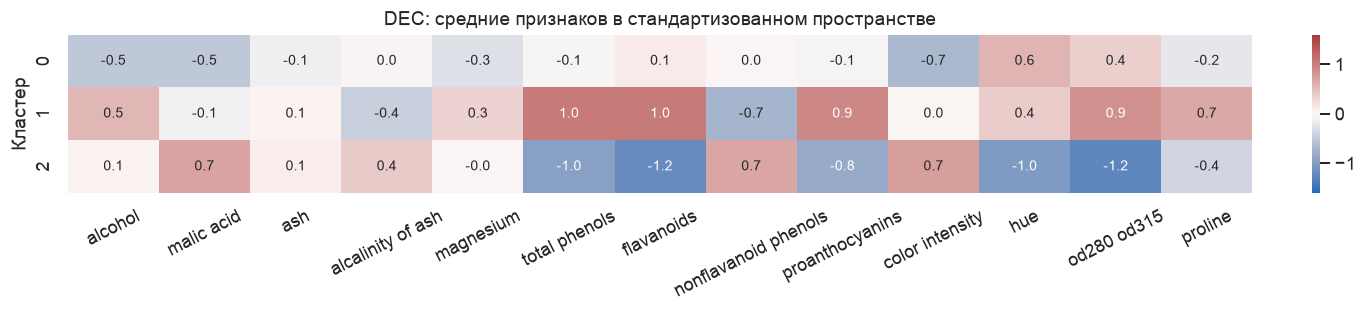

In [32]:
dec_centers = pd.DataFrame(cluster_centers(X_scaled, labels_dec), columns=X_raw.columns)
dec_profiles = pd.DataFrame(scaler.inverse_transform(dec_centers.to_numpy()), columns=X_raw.columns)
display(dec_profiles.round(3))
dec_profiles.to_csv(RESULTS / "dec_profiles.csv", index_label="Кластер")

fig, ax = plt.subplots(figsize=(11.8, 2.6), layout="constrained")
sns.heatmap(dec_centers.rename(columns=lambda s: s.replace("_", " ")), annot=True,
            fmt=".1f", cmap="vlag", center=0, vmin=-1.6, vmax=1.6, ax=ax, annot_kws={"fontsize": 9})
ax.set(title="DEC: средние признаков в стандартизованном пространстве", ylabel="Кластер")
ax.tick_params(axis="x", labelrotation=27)
fig.savefig(FIGURES / "dec_profiles.png", dpi=150)
plt.show()

У группы 0 DEC самая низкая средняя интенсивность цвета, 3,498. У группы 1 самые высокие средние значения пролина (954,696) и флавоноидов (3,065). Группа 2 выделяется интенсивностью цвета 6,764 и самым низким уровнем флавоноидов 0,843. Центры описывают найденные группы в исходных признаках.

In [33]:
summary = {
    "rows": len(X_raw), "features": X_raw.shape[1],
    "outlier_rows": int(outlier_rows.sum()),
    "pca_explained_ratio": pca.explained_variance_ratio_.tolist(),
    "elbow_k": elbow_k, "kmeans_k": kmeans_k, "ward_k": ward_k,
    "ward_height": float(height),
    "kmeans_inertia": float(kmeans.inertia_),
    "classical_stability": json.loads(robustness.to_json(orient="records")),
    "comparison": json.loads(comparison.to_json(orient="index")),
    "deep": deep_summary,
}
(RESULTS / "summary.json").write_text(json.dumps(summary, ensure_ascii=False, indent=2), encoding="utf-8")

5042

## Выводы

Для 178 образцов Wine оба классических метода выделили по три группы. K-means дал силуэт 0,2849 и ARI с сортами 0,8975 и сохранил разбиение на 161 объекте после исключения IQR-выбросов. У DEC силуэт в общем пространстве равен 0,1792, у метода Уорда 0,2774. Независимые повторы DEC также меняли состав групп. Для этого набора и проверенных настроек предпочтительнее K-means.

## Список источников

1. Гандлин А. Снижение размерности и латентные факторы // Математика для анализа данных. – URL: https://contest.yandex.ru/tracks/math/linear-algebra/dimensionality-reduction-and-latent-factors (дата обращения: 11.11.2026).

2. Глубокая кластеризация : дополнительное задание к лабораторной работе 3 // Системы искусственного интеллекта и машинное обучение : электронный курс НГТУ. – URL: https://dispace.nstu.ru/course/965/33534/84294 (дата обращения: 10.11.2026).

3. Кантор В. Кластеризация // Учебник по машинному обучению. – URL: https://contest.yandex.ru/tracks/ml/practical-topics/clustering (дата обращения: 11.11.2026).

4. Лабораторная работа 3. Кластеризация : методические указания // Системы искусственного интеллекта и машинное обучение : электронный курс НГТУ. – URL: https://dispace.nstu.ru/course/965/17799/44065 (дата обращения: 10.11.2026).

5. Лемешко Б. Ю. Критерии проверки отклонения распределения от нормального закона : руководство по применению. – Москва : ИНФРА-М, 2015. – 159, [1] с. – ISBN 978-5-16-010314-3. – DOI 10.12737/6086.

6. Нейчев Р. Тонкости обучения // Учебник по машинному обучению. – URL: https://contest.yandex.ru/tracks/ml/deep-learning-introduction/training-techniques (дата обращения: 11.11.2026).

7. Федотов С., Синицин Ф. Машинное обучение // Учебник по машинному обучению. – URL: https://contest.yandex.ru/tracks/ml/introduction/machine-learning (дата обращения: 11.11.2026).

8. Aeberhard S., Forina M. Wine : набор данных // UCI Machine Learning Repository. – 1992. – DOI 10.24432/C5PC7J. – URL: https://archive.ics.uci.edu/dataset/109/wine (дата обращения: 11.11.2026). – Лицензия CC BY 4.0.

9. Clustering // Scikit-learn : документация. – URL: https://scikit-learn.org/stable/modules/clustering.html (дата обращения: 11.11.2026).

10. Intro to Autoencoders // TensorFlow : документация. – URL: https://www.tensorflow.org/tutorials/generative/autoencoder (дата обращения: 11.11.2026).

11. Van der Maaten L., Hinton G. Visualizing Data using t-SNE // Journal of Machine Learning Research. – 2008. – Vol. 9. – P. 2579–2605. – URL: https://www.jmlr.org/papers/v9/vandermaaten08a.html (дата обращения: 11.11.2026).

12. Xie J., Girshick R., Farhadi A. Unsupervised Deep Embedding for Clustering Analysis // Proceedings of the 33rd International Conference on Machine Learning. – PMLR, 2016. – Vol. 48. – P. 478–487. – URL: https://proceedings.mlr.press/v48/xieb16.html (дата обращения: 11.11.2026).